# 03 · Data cleaning

Remove structural failures and exact duplicates while preserving an audit trail.

Run notebooks **01 → 09** in order. This notebook contains its implementation directly; it does not import project code from `src/`.

In [1]:
from pathlib import Path
import json
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
out = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
out.mkdir(parents=True, exist_ok=True)
reports.mkdir(parents=True, exist_ok=True)

In [2]:
def load_manifest(name):
    path = out / name
    if not path.exists():
        raise FileNotFoundError(f"Run the preceding notebook first: {path}")
    return [json.loads(line) for line in path.read_text().splitlines()]

def save_manifest(name, rows):
    path = out / name
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as stream:
        for row in rows:
            stream.write(json.dumps(row, allow_nan=False) + "\n")

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

## Group exact PCM duplicates

The identity includes sample rate and channel count. Conflicting labels are quarantined; otherwise the lexicographically first ID is retained.

### Math for the next code block — exact-audio equivalence

Two records are treated as exact duplicates when

$$r_i\sim r_j\iff
(f_{s,i},C_i,h_i)=(f_{s,j},C_j,h_j),$$

where $f_s$ is sample rate, $C$ is channel count, and $h$ is the SHA-256 digest of PCM bytes. Including format prevents equal byte strings at different sample rates from being treated as the same sound.

In [3]:
profiled = load_manifest("02_profiled.jsonl")
groups, kept, excluded = defaultdict(list), [], []
for row in profiled:
    if not row["valid"] or row.get("rms",0)==0:
        excluded.append({**row,"exclusion_reason":"invalid_or_zero_energy"})
    else:
        groups[(row["sample_rate"],row["channels"],row["pcm_sha256"])].append(row)

### Math for the next code block — deterministic retention

For duplicate group $G$, the code applies

$$|\{y_i:i\in G\}|>1\Rightarrow\text{quarantine all records},$$

otherwise it retains $\arg\min_{i\in G}\operatorname{id}_i$ and records every other member as an exact duplicate. The minimum is lexical, so the result does not depend on input order.

In [4]:
for group in groups.values():
    group.sort(key=lambda row:row["id"])
    if len({row["word"] for row in group})>1:
        excluded.extend({**row,"exclusion_reason":"conflicting_labels_same_audio"} for row in group)
    else:
        kept.append(group[0])
        excluded.extend({**row,"exclusion_reason":"exact_duplicate","retained_id":group[0]["id"]}
                        for row in group[1:])
cleaned = sorted(kept,key=lambda row:row["id"])
save_manifest("03_cleaned.jsonl",cleaned); save_manifest("03_excluded.jsonl",excluded)

In [5]:
reasons = Counter(row["exclusion_reason"] for row in excluded)
display({"raw":len(profiled),"retained":len(cleaned),"excluded":len(excluded),"reasons":dict(reasons)})
display([{key:r.get(key) for key in ("id","word","exclusion_reason","retained_id")} for r in excluded[:5]])

{'raw': 8000,
 'retained': 7973,
 'excluded': 27,
 'reasons': {'exact_duplicate': 27}}

[{'id': 'down__c120e80e_nohash_4',
  'word': 'down',
  'exclusion_reason': 'exact_duplicate',
  'retained_id': 'down__c120e80e_nohash_1'},
 {'id': 'down__c120e80e_nohash_5',
  'word': 'down',
  'exclusion_reason': 'exact_duplicate',
  'retained_id': 'down__c120e80e_nohash_2'},
 {'id': 'go__28ce0c58_nohash_3',
  'word': 'go',
  'exclusion_reason': 'exact_duplicate',
  'retained_id': 'go__28ce0c58_nohash_2'},
 {'id': 'go__c120e80e_nohash_6',
  'word': 'go',
  'exclusion_reason': 'exact_duplicate',
  'retained_id': 'go__c120e80e_nohash_3'},
 {'id': 'go__cb2929ce_nohash_6',
  'word': 'go',
  'exclusion_reason': 'exact_duplicate',
  'retained_id': 'go__cb2929ce_nohash_0'}]

## Cleaning result

Low-level and saturation flags remain in the retained manifest.

In [6]:
INK, MUTED, BLUE, TEAL, AMBER, RED = "#152b42", "#586c7d", "#3265bb", "#087f8c", "#ba6b10", "#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white",
                     "axes.edgecolor":"#c8d5e2", "axes.labelcolor":INK,
                     "xtick.color":MUTED, "ytick.color":MUTED, "font.size":11})

def finish_figure(fig, name):
    directory = reports / "figures"
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(directory / f"{name}.svg", bbox_inches="tight")
    plt.show()

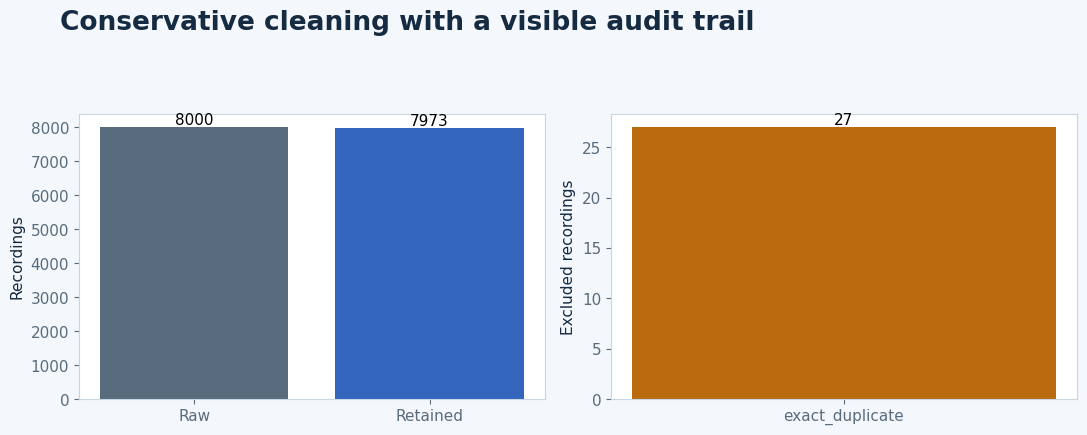

In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
bars=axes[0].bar(["Raw","Retained"],[len(profiled),len(cleaned)],color=[MUTED,BLUE]); axes[0].bar_label(bars); axes[0].set(ylabel="Recordings")
bars=axes[1].bar(list(reasons),list(reasons.values()),color=AMBER); axes[1].bar_label(bars); axes[1].set(ylabel="Excluded recordings")
fig.suptitle("Conservative cleaning with a visible audit trail",x=.06,ha="left",fontsize=19,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.88)); finish_figure(fig,"03_cleaning")

Continue with [04 · Dataset splitting](04_dataset_splitting.ipynb).